In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/uciml/autompg-dataset/auto-mpg.csv


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv('/kaggle/input/datasets/uciml/autompg-dataset/auto-mpg.csv')

df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [6]:
df['horsepower'] = df['horsepower'].replace('?', np.nan)

df['horsepower'] = pd.to_numeric(df['horsepower'])

df['horsepower'] = df['horsepower'].fillna(df['horsepower'].mean())

print(df['horsepower'].isnull().sum())

0


In [7]:
X = df[['horsepower']]
y = df['mpg']

print(X.shape)
print(y.shape)

(398, 1)
(398,)


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape)
print(X_test.shape)

(318, 1)
(80, 1)


In [9]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

print(X_train_poly.shape)

(318, 3)


In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_poly)
X_test_scaled = scaler.transform(X_test_poly)

print(X_train_scaled.shape)

(318, 3)


In [11]:
def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

In [12]:
n_features = X_train_scaled.shape[1]

weights = np.zeros(n_features)
bias = 0.0

print(weights)
print(bias)

[0. 0. 0.]
0.0


In [13]:
learning_rate = 0.01
epochs = 1000
batch_size = 32
momentum = 0.9
velocity_weights = np.zeros(n_features)
velocity_bias = 0.0

In [14]:
X_train_values = X_train_scaled
y_train_values = y_train.to_numpy()

n = len(y_train_values)

loss_history = []

print(n)

318


In [15]:
for epoch in range(epochs):

    indices = np.random.permutation(n)

    for start in range(0, n, batch_size):

        batch_indices = indices[start:start + batch_size]

        X_batch = X_train_values[batch_indices]
        y_batch = y_train_values[batch_indices]

        predictions = X_batch @ weights + bias

        errors = predictions - y_batch

        gradients = (2 / len(y_batch)) * (X_batch.T @ errors)
        bias_gradient = (2 / len(y_batch)) * np.sum(errors)

        # Update using Momentum
        velocity_weights = momentum * velocity_weights + learning_rate * gradients
        velocity_bias = momentum * velocity_bias + learning_rate * bias_gradient

        weights = weights - velocity_weights
        bias = bias - velocity_bias

    y_pred = X_train_values @ weights + bias
    loss = mse(y_train_values, y_pred)

    loss_history.append(loss)

    if epoch % 100 == 0:
        print("Epoch:", epoch, "Loss:", loss)

Epoch: 0 Loss: 83.80010349191228
Epoch: 100 Loss: 21.68645986978499
Epoch: 200 Loss: 21.68093703065578
Epoch: 300 Loss: 21.723963441334668
Epoch: 400 Loss: 21.705871652155015
Epoch: 500 Loss: 21.688799095977362
Epoch: 600 Loss: 21.68507820808591
Epoch: 700 Loss: 21.682096226134565
Epoch: 800 Loss: 21.68039650752915
Epoch: 900 Loss: 21.679702817138114


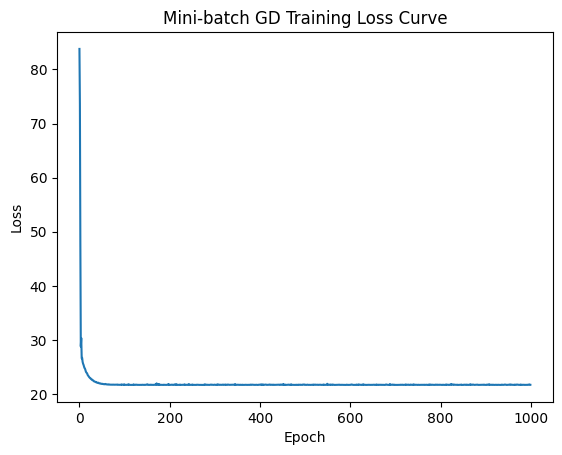

In [16]:
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Mini-batch GD Training Loss Curve")
plt.show()

In [17]:
y_test_pred = X_test_scaled @ weights + bias

test_mse = mse(y_test.to_numpy(), y_test_pred)
test_rmse = np.sqrt(test_mse)

print("Test MSE:", test_mse)
print("Test RMSE:", test_rmse)

Test MSE: 13.826391582386123
Test RMSE: 3.7183856150735797


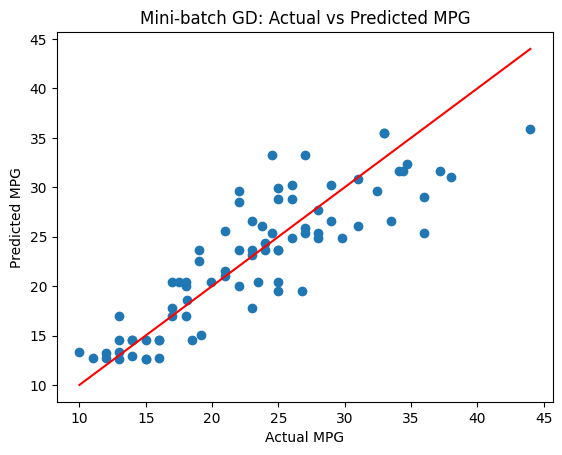

In [18]:
plt.scatter(y_test, y_test_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red'
)

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("Mini-batch GD: Actual vs Predicted MPG")
plt.show()

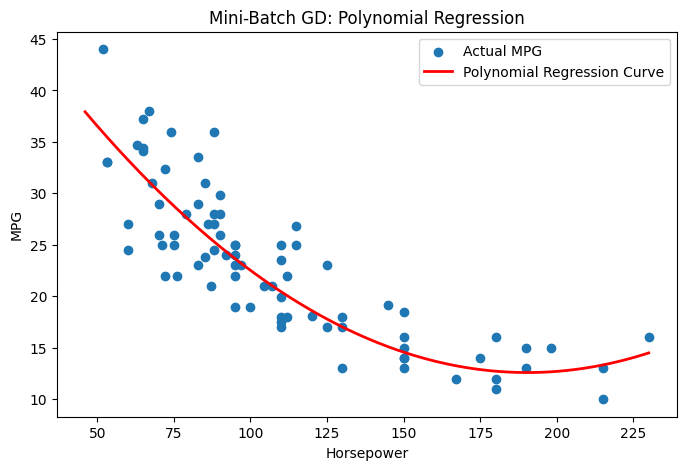

In [19]:
horsepower_range = np.linspace(
    X['horsepower'].min(),
    X['horsepower'].max(),
    200
).reshape(-1, 1)

horsepower_grid = pd.DataFrame({
    'horsepower': horsepower_range.flatten()
})

horsepower_poly = poly.transform(horsepower_grid)
horsepower_scaled = scaler.transform(horsepower_poly)

predicted_curve = horsepower_scaled @ weights + bias

plt.figure(figsize=(8, 5))
plt.scatter(X_test['horsepower'], y_test, label='Actual MPG')

plt.plot(
    horsepower_range,
    predicted_curve,
    color='red',
    linewidth=2,
    label='Polynomial Regression Curve'
)

plt.xlabel('Horsepower')
plt.ylabel('MPG')
plt.title('Mini-Batch GD: Polynomial Regression')
plt.legend()
plt.show()